In [1]:
import pandas as pd
import numpy as np
from basin import *
from MultiAgent_DQ import *
import sys
sys.path.append('../')
from utils import *

In [5]:
# Parameters
t = 1
s = 0
r = 0.8
p = 0.4
epsilon = 0.1
d = 0.6
alpha = 0.3
bound = 1 / (1 - d)

In [6]:

def trim_q_by_strategy(q1, q2, s1, s2):
    """
    Trim q1 and q2 sequences based on their respective initial strategy orderings.
    Both sequences are cut to the same length, determined by when *either* violates
    its initial ordering — whichever lasts longer determines the trim point.
    
    Parameters
    ----------
    q1, q2 : pd.DataFrame or np.ndarray
        Time × features (Q-values). Must have same length along time axis.
    s1, s2 : str
        Strategies for q1 and q2, each one of {"AD","GT","AGT","AC"}.
        
    Returns
    -------
    q1_trimmed, q2_trimmed : same type as input
        Trimmed sequences up to the last timestep where both maintain initial ordering.
    """
    
    # Convert to numpy if DataFrames
    q1_arr = q1.values if hasattr(q1, "values") else np.asarray(q1)
    q2_arr = q2.values if hasattr(q2, "values") else np.asarray(q2)
    
    def ordering_sign(Q, strategy):
        """
        Compute sign of (defect - coop) according to strategy from a 2x2 Q-matrix or row pair.
        Positive sign → defect > coop, Negative → coop > defect.
        """
        delta = Q[1] - Q[0]
        if strategy in ["GT", "AC"]:
            delta = -delta
        return np.sign(delta)
    
    def valid_length(Q, strategy):
        """Return how long ordering stays consistent with the initial."""
        # Use first two timesteps as reference
        ref_sign = ordering_sign(Q[:2], strategy)
        last_valid_idx = 1
        for t in range(1, Q.shape[0]):
            cur_sign = ordering_sign(Q[t-1:t+1], strategy)
            if np.all(cur_sign == ref_sign):
                last_valid_idx = t
            else:
                break
        return last_valid_idx + 1  # inclusive index
    
    len1 = valid_length(q1_arr, s1)
    len2 = valid_length(q2_arr, s2)
    
    # Cut based on whichever lasts longer
    cut_len = min(len1, len2) 
    
    if hasattr(q1, "iloc"):
        return q1.iloc[:cut_len], q2.iloc[:cut_len]
    else:
        return q1_arr[:cut_len], q2_arr[:cut_len]


Using seed: 994992297
Running pair: (AD, GT)


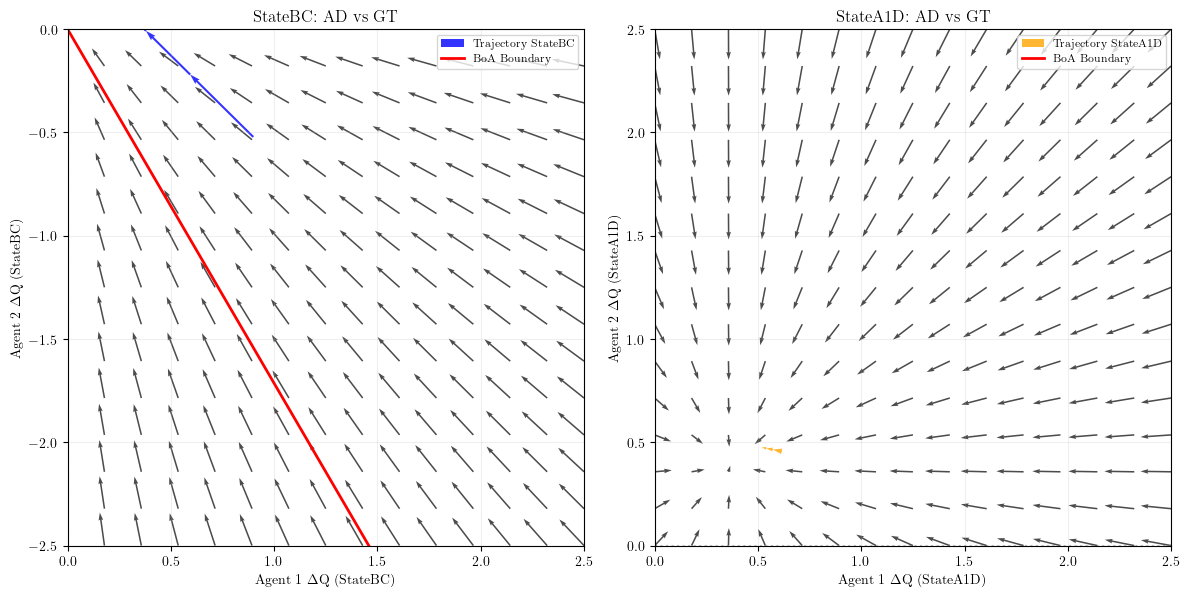

In [7]:
# Strategy pairs
strategy_pairs = [("AD","GT")
    #("AD","AD"), ("AD","GT"), ("AD","AGT"), ("AD","AC"),
    #("GT","AD"), ("GT","GT"), ("GT","AGT"), ("GT","AC"),
    #("AGT","AD"), ("AGT","GT"), ("AGT","AGT"), ("AGT","AC"),
    #("AC","AD"), ("AC","GT"), ("AC","AGT"), 
    #("AC","AC")
]
stop_when_cross = True
# Map opponent strategy to function
func_map = {
    "AD": QvaluesADvsAD,
    "GT": QvaluesGTvsGT,
    "AGT": QvaluesADvsAGT,
    "AC": QvaluesADvsAC
}
randomseeds = np.random.randint(1, 1020131031, size=1)  # 5 is exclusive

for seed in randomseeds:
    np.random.seed(seed)
    print(f"Using seed: {seed}")
    for s1, s2 in strategy_pairs:
        print(f"Running pair: ({s1}, {s2})")

        # Initialize algorithm with fixed strategy pair
        algo = Algorithm(
            e=epsilon, lambda_val=0, alpha=alpha, delta=d,
            init_mode='fixed', tolerance=1e-10000, 
            M=50, strategy1=s1, strategy2=s2, verbose=False
        )

        # Run the algorithm
        q1_history_per_sample_algo, q2_history_per_sample_algo, batch_times_algo, timeout_out, timeout_vi = algo.run()

        # Pick a sample
        exp = np.random.randint(0, 50)
        q1 = convert_dict_to_mean_df(q1_history_per_sample_algo, mean=False)[exp]
        q2 = convert_dict_to_mean_df(q2_history_per_sample_algo, mean=False)[exp]
        if stop_when_cross:
            q1, q2 = trim_q_by_strategy(q1, q2, s1, s2)
        func1 = func_map[s2]  # x-component uses opponent strategy s2
        func2 = func_map[s1]  # y-component uses same opponent strategy
        #check if the ordering changes here input (q1, q2, s1, s2)
        # Plot vector field with strategy information
        plotter = VectorFieldAutomatic(
            q1=q1, q2=q2,
            t=t, r=r, p=p, s=s, epsilon=epsilon, d=d,
            func1=func1,
            func2=func2,
            strategy1=s1,    # Add strategy1
            strategy2=s2,    # Add strategy2
            alpha=alpha,
            density=15,
            show_trajectory=True,
            show_basin=True
        )
        
                    
                    
        plotter.plot(show_all_quadrants=False)
        
    





In [ ]:
def calculate_pi_ADGT(t=1, r=0.7, p=0.2, s=0, epsilon=0.1, d=0.6, state_idx=0):
    """
    Calculate π_ADGT (basin-of-attraction probability for ADGT configuration).
    
    Based on Proposition: π = 0.5 × min(|ΔQx|, |ΔQy|) / max(|ΔQx|, |ΔQy|)
    where ΔQx = Q^AD(0) - Q^AD(1) and ΔQy = Q^GT(0) - Q^GT(1)
    
    Parameters:
    -----------
    t, r, p, s : float
        Prisoner's dilemma payoffs
    epsilon : float
        Exploration parameter
    d : float
        Discount factor
    state_idx : int
        State index: 0 for StateBC, 1 for StateA1D
    
    Returns:
    --------
    float : π_ADGT value
    """
    func_map = {
        "AD": QvaluesADvsAD,
        "GT": QvaluesGTvsGT
    }
    
    Q1 = func_map["AD"](t, r, p, s, epsilon, d)[state_idx]
    Q2 = func_map["GT"](t, r, p, s, epsilon, d)[state_idx]
    
    ΔQx = Q1[0] - Q1[1]  # Q^AD(0) - Q^AD(1)
    ΔQy = Q2[0] - Q2[1]  # Q^GT(0) - Q^GT(1)
    
    if np.isclose(ΔQx, 0.0) or np.isclose(ΔQy, 0.0):
        return 0.0
    
    # Formula from proposition
    pi = 0.5 * min(abs(ΔQx), abs(ΔQy)) / max(abs(ΔQx), abs(ΔQy))
    return max(0.0, min(1.0, pi))


def calculate_equilibrium_probability_proposition(strategy1, strategy2, pi_ADGT, t=1, r=0.7, p=0.2, s=0, epsilon=0.1, d=0.6, state_idx=0):
    """
    Calculate P(GTGT) according to Proposition (Refined basin-of-attraction bounds).
    
    Implements the categorization from the proposition:
    1. Equilibria (2): (GT,GT) and (AD,AD)
    2. Deterministic to AD (6): (AD,AGT), (AGT,AD), (AC,AD), (AD,AC), (AGT,AGT)
    3. Single basin (2): (AD,GT) and (GT,AD) → P(GTGT) = π_ADGT
    4. Symmetric (2): (GT,AC) and (AC,GT) → P(GTGT) = 1/2
    5. Multi-step with bounds (4): Various bounds
    
    Parameters:
    -----------
    strategy1, strategy2 : str
        Strategies for player 1 and 2
    pi_ADGT : float
        Pre-calculated π_ADGT value
    t, r, p, s, epsilon, d : float
        Game parameters
    state_idx : int
        State index
    
    Returns:
    --------
    dict with P_GTGT, P_GTGT_min, P_GTGT_max, case, category
    """
    # Normalize symmetric cases
    if (strategy1 == 'AD' and strategy2 == 'GT') or (strategy1 == 'GT' and strategy2 == 'AD'):
        strategy1, strategy2 = 'AD', 'GT'
    if (strategy1 == 'AD' and strategy2 == 'AGT') or (strategy1 == 'AGT' and strategy2 == 'AD'):
        strategy1, strategy2 = 'AD', 'AGT'
    if (strategy1 == 'AC' and strategy2 == 'AD') or (strategy1 == 'AD' and strategy2 == 'AC'):
        strategy1, strategy2 = 'AD', 'AC'
    if (strategy1 == 'GT' and strategy2 == 'AGT') or (strategy1 == 'AGT' and strategy2 == 'GT'):
        strategy1, strategy2 = 'GT', 'AGT'
    if (strategy1 == 'GT' and strategy2 == 'AC') or (strategy1 == 'AC' and strategy2 == 'GT'):
        strategy1, strategy2 = 'GT', 'AC'
    if (strategy1 == 'AC' and strategy2 == 'AGT') or (strategy1 == 'AGT' and strategy2 == 'AC'):
        strategy1, strategy2 = 'AC', 'AGT'
    
    case_name = f"{strategy1}{strategy2}"
    
    # Category 1: Equilibria
    if case_name == 'GTGT':
        return {
            'P_GTGT': 1.0,
            'P_GTGT_min': 1.0,
            'P_GTGT_max': 1.0,
            'category': 'Equilibria',
            'case': 'GTGT (self-loop)'
        }
    if case_name == 'ADAD':
        return {
            'P_GTGT': 0.0,
            'P_GTGT_min': 0.0,
            'P_GTGT_max': 0.0,
            'category': 'Equilibria',
            'case': 'ADAD (self-loop)'
        }
    
    # Category 2: Deterministic to AD
    if case_name in ['ADAGT', 'AGTAD', 'ACAD', 'ADAC', 'AGTAGT']:
        return {
            'P_GTGT': 0.0,
            'P_GTGT_min': 0.0,
            'P_GTGT_max': 0.0,
            'category': 'Deterministic to AD',
            'case': f'{case_name} → ADAD'
        }
    
    # Category 3: Single basin (ADGT)
    if case_name == 'ADGT':
        return {
            'P_GTGT': pi_ADGT,
            'P_GTGT_min': pi_ADGT,
            'P_GTGT_max': pi_ADGT,
            'category': 'Single basin',
            'case': 'ADGT (basin of attraction)'
        }
    
    # Category 4: Symmetric (GTAC)
    if case_name in ['GTAC', 'ACGT']:
        return {
            'P_GTGT': 0.5,
            'P_GTGT_min': 0.5,
            'P_GTGT_max': 0.5,
            'category': 'Symmetric',
            'case': f'{case_name} (50/50 split)'
        }
    
    # Category 5: Multi-step with bounds
    # Case 5a: AGTGT or GTAGT
    if case_name in ['AGTGT', 'GTAGT']:
        P_GTGT_min = 0.25 * (1 + pi_ADGT)  # Lower bound: 1/4(1 + π_ADGT)
        P_GTGT_max = 0.5  # Upper bound: 1/2
        return {
            'P_GTGT': (P_GTGT_min + P_GTGT_max) / 2,  # Midpoint for display
            'P_GTGT_min': P_GTGT_min,
            'P_GTGT_max': P_GTGT_max,
            'category': 'Multi-step (bounds)',
            'case': f'{case_name} [1/4(1+π), 1/2]'
        }
    
    # Case 5b: ACAGT or AGTAC
    if case_name in ['ACAGT', 'AGTAC']:
        P_GTGT_min = 0.125 * (1 + pi_ADGT)  # Lower bound: 1/8(1 + π_ADGT)
        P_GTGT_max = 0.25  # Upper bound: 1/4
        return {
            'P_GTGT': (P_GTGT_min + P_GTGT_max) / 2,  # Midpoint for display
            'P_GTGT_min': P_GTGT_min,
            'P_GTGT_max': P_GTGT_max,
            'category': 'Multi-step (bounds)',
            'case': f'{case_name} [1/8(1+π), 1/4]'
        }
    
    # Case 5c: ACAC
    if case_name == 'ACAC':
        P_GTGT_min = 0.25 + 0.0625 * (1 + pi_ADGT)  # Lower bound: 1/4 + 1/16(1 + π_ADGT)
        P_GTGT_max = 0.375  # Upper bound: 3/8
        return {
            'P_GTGT': (P_GTGT_min + P_GTGT_max) / 2,  # Midpoint for display
            'P_GTGT_min': P_GTGT_min,
            'P_GTGT_max': P_GTGT_max,
            'category': 'Multi-step (bounds)',
            'case': 'ACAC [1/4+1/16(1+π), 3/8]'
        }
    
    # Default fallback
    return {
        'P_GTGT': 0.5,
        'P_GTGT_min': 0.0,
        'P_GTGT_max': 1.0,
        'category': 'Unknown',
        'case': f'{case_name} (unknown)'
    }

In [ ]:
import pandas as pd

# Define all 16 initial strategy profiles (reduced to 10 by symmetry)
# According to Proposition: 16 profiles partition into 5 categories
configurations = [
    ('AD', 'AD'),
    ('GT', 'GT'),
    ('AD', 'GT'),  # Also covers (GT, AD)
    ('AD', 'AGT'),  # Also covers (AGT, AD)
    ('AD', 'AC'),   # Also covers (AC, AD)
    ('AGT', 'AGT'),
    ('GT', 'AGT'),  # Also covers (AGT, GT)
    ('GT', 'AC'),   # Also covers (AC, GT)
    ('AC', 'AGT'),  # Also covers (AGT, AC)
    ('AC', 'AC')
]

# Define two payoff examples to compare
payoff_examples = [
    {
        'name': 'Example 1',
        't': 1,
        'r': 0.7,
        'p': 0.2,
        's': 0,
        'epsilon': 0.1,
        'd': 0.6,
        'state_idx': 0  # StateBC
    },
    {
        'name': 'Example 2',
        't': 1,
        'r': 0.8,
        'p': 0.3,
        's': 0,
        'epsilon': 0.1,
        'd': 0.6,
        'state_idx': 0  # StateBC
    }
]

# Store results for both examples
all_results = []

for example in payoff_examples:
    params = {k: v for k, v in example.items() if k != 'name'}
    
    # Calculate π_ADGT first (needed for bounds)
    pi_ADGT = calculate_pi_ADGT(**params)
    
    # Calculate probabilities for each configuration
    results = []
    for s1, s2 in configurations:
        result = calculate_equilibrium_probability_proposition(
            s1, s2, pi_ADGT, **params
        )
        
        # Calculate P(ADAD) = 1 - P(GTGT)
        P_ADAD = 1 - result['P_GTGT']
        P_ADAD_min = 1 - result['P_GTGT_max']  # Note: min/max swap for ADAD
        P_ADAD_max = 1 - result['P_GTGT_min']
        
        results.append({
            'Configuration': f'{s1}-{s2}',
            'P(GTGT)': result['P_GTGT'],
            'P(GTGT)_min': result['P_GTGT_min'],
            'P(GTGT)_max': result['P_GTGT_max'],
            'P(ADAD)': P_ADAD,
            'P(ADAD)_min': P_ADAD_min,
            'P(ADAD)_max': P_ADAD_max,
            'Category': result['category'],
            'Case': result['case']
        })
    
    # Create DataFrame
    df = pd.DataFrame(results)
    
    # Calculate aggregate bounds (averaging over all 16 profiles)
    # According to Proposition: E[P(GTGT)] ∈ [1/16(3.125 + 2.875π), 1/16(3.875 + 2π)]
    # But we need to account for the fact that some configurations appear twice (symmetry)
    # The 10 configurations represent: 2×1 + 1×2 + 5×2 + 1×2 + 1×2 = 16 total profiles
    
    # Count multiplicities: each config in our list represents 1 or 2 profiles
    multiplicities = {
        'AD-AD': 1, 'GT-GT': 1,  # Equilibria: 1 each
        'AD-GT': 2,  # Single basin: 2 (AD,GT) and (GT,AD)
        'AD-AGT': 2, 'AD-AC': 2, 'AGT-AGT': 1,  # Deterministic to AD: 5 total
        'GT-AGT': 2,  # Multi-step: 2
        'GT-AC': 2,  # Symmetric: 2
        'AC-AGT': 2, 'AC-AC': 1  # Multi-step: 3 total
    }
    
    # Calculate weighted sum for aggregate
    total_P_GTGT = 0
    total_P_GTGT_min = 0
    total_P_GTGT_max = 0
    
    for _, row in df.iterrows():
        mult = multiplicities.get(row['Configuration'], 1)
        total_P_GTGT += row['P(GTGT)'] * mult
        total_P_GTGT_min += row['P(GTGT)_min'] * mult
        total_P_GTGT_max += row['P(GTGT)_max'] * mult
    
    # Expected value over 16 profiles
    E_P_GTGT = total_P_GTGT / 16
    E_P_GTGT_min = total_P_GTGT_min / 16
    E_P_GTGT_max = total_P_GTGT_max / 16
    
    # Also calculate using proposition formula for verification
    E_P_GTGT_prop_min = (3.125 + 2.875 * pi_ADGT) / 16
    E_P_GTGT_prop_max = (3.875 + 2 * pi_ADGT) / 16
    
    # Add summary row
    summary_row = {
        'Configuration': 'AGGREGATE (E[P(GTGT)])',
        'P(GTGT)': E_P_GTGT,
        'P(GTGT)_min': E_P_GTGT_min,
        'P(GTGT)_max': E_P_GTGT_max,
        'P(ADAD)': 1 - E_P_GTGT,
        'P(ADAD)_min': 1 - E_P_GTGT_max,
        'P(ADAD)_max': 1 - E_P_GTGT_min,
        'Category': 'Aggregate',
        'Case': f'Proposition bounds: [{E_P_GTGT_prop_min:.4f}, {E_P_GTGT_prop_max:.4f}]',
        'E_P_GTGT_prop_min': E_P_GTGT_prop_min,
        'E_P_GTGT_prop_max': E_P_GTGT_prop_max
    }
    
    df = pd.concat([df, pd.DataFrame([summary_row])], ignore_index=True)
    
    # Add example info
    df['Example'] = example['name']
    df['π_ADGT'] = pi_ADGT
    
    all_results.append(df)

# Combine results
df_combined = pd.concat(all_results, ignore_index=True)

# Display results
print("=" * 100)
print("REFINED BASIN-OF-ATTRACTION BOUNDS (Proposition)")
print("=" * 100)

for example in payoff_examples:
    df_example = df_combined[df_combined['Example'] == example['name']].copy()
    
    print(f"\n{example['name']}: t={example['t']}, r={example['r']}, p={example['p']}, "
          f"s={example['s']}, ε={example['epsilon']}, δ={example['d']}")
    
    pi_val = df_example['π_ADGT'].iloc[0]
    print(f"π_ADGT = {pi_val:.6f}\n")
    
    # Display main table (without aggregate row for cleaner display)
    df_display = df_example[df_example['Configuration'] != 'AGGREGATE (E[P(GTGT)])'].copy()
    
    # Format for display
    display_cols = ['Configuration', 'Category', 'P(GTGT)', 'P(GTGT)_min', 'P(GTGT)_max', 'Case']
    if any('[' in str(c) for c in df_display['Case']):
        # For bounds cases, show range
        df_display['P(GTGT)_range'] = df_display.apply(
            lambda row: f"[{row['P(GTGT)_min']:.4f}, {row['P(GTGT)_max']:.4f}]" 
            if row['P(GTGT)_min'] != row['P(GTGT)_max'] 
            else f"{row['P(GTGT)']:.4f}",
            axis=1
        )
        display_cols = ['Configuration', 'Category', 'P(GTGT)_range', 'Case']
    
    print(df_display[display_cols].to_string(index=False))
    
    # Display aggregate bounds
    agg_row = df_example[df_example['Configuration'] == 'AGGREGATE (E[P(GTGT)])'].iloc[0]
    print(f"\n{'='*100}")
    print(f"Aggregate Expected Value: E[P(GTGT)] = {agg_row['P(GTGT)']:.6f}")
    print(f"Bounds: [{agg_row['P(GTGT)_min']:.6f}, {agg_row['P(GTGT)_max']:.6f}]")
    if 'E_P_GTGT_prop_min' in agg_row:
        print(f"Proposition formula bounds: [{agg_row['E_P_GTGT_prop_min']:.6f}, {agg_row['E_P_GTGT_prop_max']:.6f}]")
    print(f"{'='*100}\n")

# Create comprehensive comparison table
print("\n" + "=" * 100)
print("COMPARISON TABLE: Both Examples")
print("=" * 100)

# Pivot table for comparison
comparison_cols = ['Configuration', 'Category', 'P(GTGT)', 'P(GTGT)_min', 'P(GTGT)_max']
df_comparison = df_combined[df_combined['Configuration'] != 'AGGREGATE (E[P(GTGT)])'][
    comparison_cols + ['Example']
].copy()

# Create pivot
df_pivot = df_comparison.pivot_table(
    index=['Configuration', 'Category'],
    columns='Example',
    values=['P(GTGT)', 'P(GTGT)_min', 'P(GTGT)_max'],
    aggfunc='first'
).reset_index()

# Flatten column names
df_pivot.columns = ['_'.join(col).strip('_') if col[1] else col[0] for col in df_pivot.columns.values]

print("\nP(GTGT) Comparison:")
display_cols = ['Configuration', 'Category'] + [c for c in df_pivot.columns if 'P(GTGT)' in c and 'min' not in c and 'max' not in c]
print(df_pivot[display_cols].to_string(index=False))

# Display aggregate comparison
print("\n" + "=" * 100)
print("Aggregate E[P(GTGT)] Comparison:")
agg_comparison = df_combined[df_combined['Configuration'] == 'AGGREGATE (E[P(GTGT)])'][
    ['Example', 'π_ADGT', 'P(GTGT)', 'P(GTGT)_min', 'P(GTGT)_max']
].copy()
print(agg_comparison.to_string(index=False))
print("=" * 100)

# Also create styled display
display(df_combined.style.format({
    'P(GTGT)': '{:.6f}',
    'P(GTGT)_min': '{:.6f}',
    'P(GTGT)_max': '{:.6f}',
    'P(ADAD)': '{:.6f}',
    'π_ADGT': '{:.6f}'
}).set_table_styles([
    {'selector': 'th', 'props': [('text-align', 'left')]},
    {'selector': 'td', 'props': [('text-align', 'left')]}
]))

EQUILIBRIUM PROBABILITIES FOR ALL CONFIGURATIONS

Parameters: t=1, r=0.7, p=0.2, s=0, ε=0.1, δ=0.6, State=0 (StateBC)

Configuration  P(ADAD)  P(GTGT)  π (basin)                                Case
        AD-AD 1.000000 0.000000   0.000000                    ADAD (self-loop)
        AD-GT 0.618068 0.381932   0.381932          ADGT (basin of attraction)
        GT-GT 0.000000 1.000000   0.000000                    GTGT (self-loop)
       AD-AGT 1.000000 0.000000   0.000000                        ADAGT → ADAD
        AD-AC 1.000000 0.000000   0.000000                         ADAC → ADAD
      AGT-AGT 1.000000 0.000000   0.000000                       AGTAGT → ADAD
       GT-AGT 0.333882 0.666118   0.422175                      GTAGT (bounds)
        GT-AC 0.500000 0.500000   0.000000                  GTAC (50/50 split)
       AC-AGT 0.500000 0.500000   0.384068 ACAGT (needs A1D state calculation)
        AC-AC 0.500000 0.500000   0.500000                    ACAC (symmetric)
          SU

,Configuration,P(ADAD),P(GTGT),π (basin),Case
0,AD-AD,1.0000,0.0000,0.0000,ADAD (self-loop)
1,AD-GT,0.6181,0.3819,0.3819,ADGT (basin of attraction)
2,GT-GT,0.0000,1.0000,0.0000,GTGT (self-loop)
3,AD-AGT,1.0000,0.0000,0.0000,ADAGT → ADAD
4,AD-AC,1.0000,0.0000,0.0000,ADAC → ADAD
5,AGT-AGT,1.0000,0.0000,0.0000,AGTAGT → ADAD
6,GT-AGT,0.3339,0.6661,0.4222,GTAGT (bounds)
7,GT-AC,0.5000,0.5000,0.0000,GTAC (50/50 split)
8,AC-AGT,0.5000,0.5000,0.3841,ACAGT (needs A1D state calculation)
9,AC-AC,0.5000,0.5000,0.5000,ACAC (symmetric)


In [16]:
calculate_equilibrium_probability('AD', 'GT')

{'P_ADAD': np.float64(0.6180675909878677),
 'P_GTGT': np.float64(0.3819324090121324),
 'pi': np.float64(0.3819324090121324),
 'case': 'ADGT (basin of attraction)',
 'ΔQx': np.float64(0.20500000000000002),
 'ΔQy': np.float64(-0.2683720930232554)}

In [ ]:
#ORGANIZE THE DESCRIPTION:
#BBoA = BoundaryBasinOfAttraction
#first you plot ADAD and then GTGT #equilibria
#plot two side of bboa
#the case in which just the bboa decide in which equilibria we will go
#AD-GT: if you start below the bboa you will definetely go to GT, if you start on top of the bboa you will go to AD (top-right quadrant)
# target remains in the top right quadrant


#AD - AGT: we don't have the bboa, in any initialization will go to ADAD, there is nothing different can happen, mention ADAD plot.
#AD - AC: the only place top boundary but there are
# two options (which axes we cross first in A1D state or BC state): A1D first) so agent2 is switching from cooperating to defecting in the A1D state, 
# but it still cooperating in the BC state, so agent 2 is switching to play GT, and player1 is still playing AD, so we need to look at AD-GT case,
# so now the moment in which cross the axes on the left hand side determines looking at the point on the right hand side whether you go to AD or GT.
#2 option) we are crossing first in the BC state, so we go to AD-AGT, and we definetely go to ADAD as discussed above

#AC-AC: 
#cross A1D (right of the boundary): 
#cross BC  (right of the boundary):
#cross A1D (left of the boundary ):
#cross BC  (left of the boundary first): cross on the right hadn boundary, they will end up in AGT-AC, we come into this plot from the left
# ACAC can lead to AGT-AC, GT-AC, AC-AGT, AC-GT, and from those situation where can I go?


